# Bank Marketing Subscription Prediction

## 01 - Dataset Understanding

**Objective:** Understand the Bank Marketing dataset before preprocessing and model development.

**Dataset:** Bank Marketing UCI

In [ ]:
# Python libraries will be imported in this notebook.


In [1]:
# ==========================================
# PHASE 2: DATASET UNDERSTANDING
# ==========================================

# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Pandas version: 3.1.0
NumPy version: 2.4.6


In [2]:
# ==========================================
# LOAD BANK MARKETING DATASET
# ==========================================

from pathlib import Path

DATA_PATH = Path("../data/raw/bank.csv")

df = pd.read_csv(DATA_PATH, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (4521, 17)


In [3]:
# First five records
print("FIRST FIVE RECORDS")
display(df.head())

# Last five records
print("LAST FIVE RECORDS")
display(df.tail())

FIRST FIVE RECORDS


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


LAST FIVE RECORDS


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
4516,33,services,married,secondary,no,-333,yes,no,cellular,30,jul,329,5,-1,0,unknown,no
4517,57,self-employed,married,tertiary,yes,-3313,yes,yes,unknown,9,may,153,1,-1,0,unknown,no
4518,57,technician,married,secondary,no,295,no,no,cellular,19,aug,151,11,-1,0,unknown,no
4519,28,blue-collar,married,secondary,no,1137,no,no,cellular,6,feb,129,4,211,3,other,no
4520,44,entrepreneur,single,tertiary,no,1136,yes,yes,cellular,3,apr,345,2,249,7,other,no


In [4]:
# Dataset verification

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Number of rows: 4521
Number of columns: 17

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data types:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 

In [5]:
# ==========================================
# STATISTICAL SUMMARY - NUMERICAL FEATURES
# ==========================================

print("NUMERICAL FEATURE SUMMARY")

display(df.describe())

NUMERICAL FEATURE SUMMARY


,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [6]:
# ==========================================
# STATISTICAL SUMMARY - CATEGORICAL FEATURES
# ==========================================

print("CATEGORICAL FEATURE SUMMARY")

display(df.describe(include=["object", "str"]))

CATEGORICAL FEATURE SUMMARY


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,4521,4521,4521,4521,4521,4521,4521,4521,4521,4521
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,yes,no,cellular,may,unknown,no
freq,969,2797,2306,4445,2559,3830,2896,1398,3705,4000


In [7]:
# ==========================================
# MISSING VALUE ANALYSIS
# ==========================================

print("MISSING VALUES PER COLUMN")

missing_values = df.isnull().sum()

display(missing_values.to_frame(name="Missing Values"))

print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

print("\nMISSING VALUE PERCENTAGE:")

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

display(
    missing_percentage.to_frame(
        name="Missing Percentage"
    )
)

MISSING VALUES PER COLUMN


,Missing Values
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



TOTAL MISSING VALUES:
0

MISSING VALUE PERCENTAGE:


,Missing Percentage
age,0.0
job,0.0
marital,0.0
education,0.0
default,0.0
balance,0.0
housing,0.0
loan,0.0
contact,0.0
day,0.0


In [8]:
# ==========================================
# DUPLICATE RECORD ANALYSIS
# ==========================================

print("TOTAL DUPLICATE RECORDS:")

duplicate_count = df.duplicated().sum()

print(duplicate_count)

print("\nDUPLICATE RECORD PERCENTAGE:")

duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print(f"{duplicate_percentage:.2f}%")

TOTAL DUPLICATE RECORDS:
0

DUPLICATE RECORD PERCENTAGE:
0.00%


### Initial Data Quality Observations

1. The dataset contains 4,521 records and 17 columns.
2. No missing values were found in any column.
3. The total number of missing values is zero.
4. No exact duplicate records were identified.
5. The dataset is structurally complete based on these checks.

These findings are based on initial inspection. Further
validation of categorical values, numerical ranges and
feature consistency will be performed in later phases.

In [9]:
# ==========================================
# TARGET VARIABLE ANALYSIS
# ==========================================

print("TARGET VARIABLE DISTRIBUTION")

# Calculate class counts
target_counts = df["y"].value_counts()

display(target_counts.to_frame(name="Count"))

# Calculate class percentages
target_percentages = (
    df["y"].value_counts(normalize=True) * 100
)

display(
    target_percentages.to_frame(
        name="Percentage"
    ).round(2)
)

print("\nTOTAL RECORDS:", len(df))
print("SUBSCRIBED CUSTOMERS:", target_counts.get("yes", 0))
print("NON-SUBSCRIBED CUSTOMERS:", target_counts.get("no", 0))

TARGET VARIABLE DISTRIBUTION


,Count
y,
no,4000
yes,521


,Percentage
y,
no,88.48
yes,11.52



TOTAL RECORDS: 4521
SUBSCRIBED CUSTOMERS: 521
NON-SUBSCRIBED CUSTOMERS: 4000


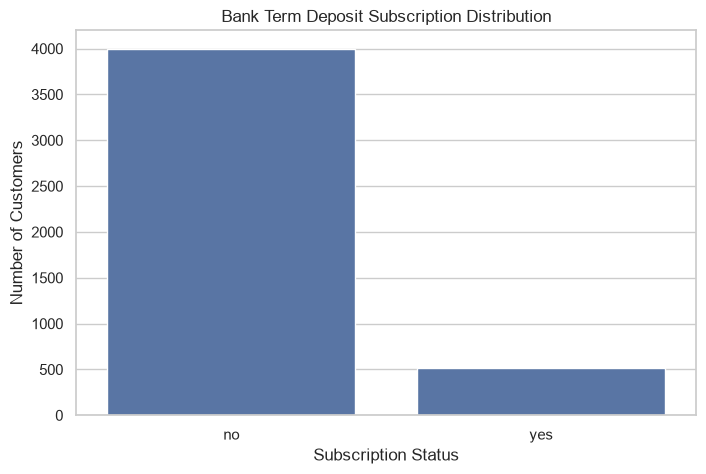

In [10]:
# ==========================================
# TARGET VARIABLE VISUALIZATION
# ==========================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="y",
    order=["no", "yes"]
)

plt.title("Bank Term Deposit Subscription Distribution")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")

plt.show()

### Target Variable Analysis – Observations

1. The target variable is `y`.
2. The dataset contains 4,521 customer records.
3. 4,000 customers (88.48%) did not subscribe.
4. 521 customers (11.52%) subscribed.
5. The target variable has two classes: yes and no.
6. The dataset exhibits class imbalance.
7. Accuracy alone may be misleading when evaluating models.
8. Precision, Recall, F1-score, ROC-AUC and PR-AUC
   will be considered during model evaluation.

**Conclusion:** The dataset is suitable for a binary
classification problem, but class imbalance must be
considered during model development and evaluation.

In [11]:
# ==========================================
# NUMERICAL AND CATEGORICAL FEATURE ANALYSIS
# ==========================================

numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Remove target from predictor lists
categorical_predictors = [
    col for col in categorical_features if col != "y"
]

print("NUMERICAL FEATURES:")
print(numerical_features)

print("\nCATEGORICAL FEATURES:")
print(categorical_predictors)

print("\nTARGET VARIABLE:")
print("y")

print("\nTOTAL NUMERICAL FEATURES:", len(numerical_features))
print("TOTAL CATEGORICAL PREDICTORS:", len(categorical_predictors))

NUMERICAL FEATURES:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

CATEGORICAL FEATURES:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

TARGET VARIABLE:
y

TOTAL NUMERICAL FEATURES: 7
TOTAL CATEGORICAL PREDICTORS: 9


/var/folders/0t/4hxrj7sn0vvg08hw1dqpc2g80000gn/T/ipykernel_1920/3290552435.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


In [12]:
# ==========================================
# ORIGINAL DATASET DOCUMENTATION
# ==========================================

with open(
    "../data/raw/bank-names.txt",
    "r",
    encoding="utf-8"
) as file:

    documentation = file.read()

print(documentation)

Citation Request:
  This dataset is public available for research. The details are described in [Moro et al., 2011]. 
  Please include this citation if you plan to use this database:

  [Moro et al., 2011] S. Moro, R. Laureano and P. Cortez. Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology. 
  In P. Novais et al. (Eds.), Proceedings of the European Simulation and Modelling Conference - ESM'2011, pp. 117-121, Guimarães, Portugal, October, 2011. EUROSIS.

  Available at: [pdf] http://hdl.handle.net/1822/14838
                [bib] http://www3.dsi.uminho.pt/pcortez/bib/2011-esm-1.txt

1. Title: Bank Marketing

2. Sources
   Created by: Paulo Cortez (Univ. Minho) and Sérgio Moro (ISCTE-IUL) @ 2012
   
3. Past Usage:

  The full dataset was described and analyzed in:

  S. Moro, R. Laureano and P. Cortez. Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology. 
  In P. Novais et al. (Eds.), Proceedings of the European S

In [13]:
# ==========================================
# EXTRACT FEATURE DESCRIPTIONS
# ==========================================

lines = documentation.splitlines()

start = None

for i, line in enumerate(lines):
    if "Input variables" in line:
        start = i
        break

if start is not None:
    print("\n".join(lines[start:]))
else:
    print("Input variables section not found.")
    print(documentation)

   Input variables:
   # bank client data:
   1 - age (numeric)
   2 - job : type of job (categorical: "admin.","unknown","unemployed","management","housemaid","entrepreneur","student",
                                       "blue-collar","self-employed","retired","technician","services") 
   3 - marital : marital status (categorical: "married","divorced","single"; note: "divorced" means divorced or widowed)
   4 - education (categorical: "unknown","secondary","primary","tertiary")
   5 - default: has credit in default? (binary: "yes","no")
   6 - balance: average yearly balance, in euros (numeric) 
   7 - housing: has housing loan? (binary: "yes","no")
   8 - loan: has personal loan? (binary: "yes","no")
   # related with the last contact of the current campaign:
   9 - contact: contact communication type (categorical: "unknown","telephone","cellular") 
  10 - day: last contact day of the month (numeric)
  11 - month: last contact month of year (categorical: "jan", "feb", "mar", ..., 

In [14]:
from pathlib import Path

dictionary_path = Path("../reports/data_dictionary.md")

print("File exists:", dictionary_path.exists())

if dictionary_path.exists():
    print("File size:", dictionary_path.stat().st_size, "bytes")
    print("\nDATA DICTIONARY PREVIEW:\n")
    print(dictionary_path.read_text(encoding="utf-8")[:2000])

File exists: True
File size: 4172 bytes

DATA DICTIONARY PREVIEW:

# ==========================================
# CREATE DATA DICTIONARY
# ==========================================

from pathlib import Path

data_dictionary = """# Bank Marketing Dataset – Data Dictionary

## Dataset Overview

- Dataset: Bank Marketing
- Source: UCI Bank Marketing dataset documentation
- Records: 4,521
- Columns: 17
- Target variable: y
- Problem type: Binary Classification

## Feature Descriptions

| Feature | Description | Data Type | Role |
|---|---|---|---|
| age | Age of the bank client | Numerical | Predictor |
| job | Type of job | Categorical | Predictor |
| marital | Marital status; divorced includes divorced or widowed | Categorical | Predictor |
| education | Education level | Categorical | Predictor |
| default | Whether the client has credit in default | Categorical | Predictor |
| balance | Average yearly balance in euros | Numerical | Predictor |
| housing | Whether the client has a hous

In [15]:
# ==========================================
# TEST DATASET INVESTIGATION
# ==========================================

from pathlib import Path
import pandas as pd

test_path = Path("../data/raw/test.csv")
submission_path = Path("../data/raw/sample submission .csv")

# Load test.csv separately using its comma delimiter
test_df = pd.read_csv(test_path, sep=",")

# Load sample submission
sample_submission = pd.read_csv(submission_path)

print("TEST DATASET SHAPE:")
print(test_df.shape)

print("\nTEST DATASET COLUMNS:")
print(test_df.columns.tolist())

print("\nTEST DATASET DATA TYPES:")
print(test_df.dtypes)

print("\nTEST DATASET FIRST 5 ROWS:")
display(test_df.head())

print("\nTEST DATASET TARGET CHECK:")
print("Target column 'y' exists:", "y" in test_df.columns)

print("\nSAMPLE SUBMISSION SHAPE:")
print(sample_submission.shape)

print("\nSAMPLE SUBMISSION COLUMNS:")
print(sample_submission.columns.tolist())

print("\nSAMPLE SUBMISSION FIRST 5 ROWS:")
display(sample_submission.head())

print("\nTRAINING DATASET COLUMNS:")
print(df.columns.tolist())

print("\nTEST AND TRAINING COLUMN COMPARISON:")
print("Columns present in training but absent in test:")
print(sorted(set(df.columns) - set(test_df.columns)))

print("\nColumns present in test but absent in training:")
print(sorted(set(test_df.columns) - set(df.columns)))

TEST DATASET SHAPE:
(427, 17)

TEST DATASET COLUMNS:
['Id', 'age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']

TEST DATASET DATA TYPES:
Id           int64
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
dtype: object

TEST DATASET FIRST 5 ROWS:


,Id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,1,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown
1,2,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown
2,3,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown
3,4,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown
4,5,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown



TEST DATASET TARGET CHECK:
Target column 'y' exists: False

SAMPLE SUBMISSION SHAPE:
(427, 2)

SAMPLE SUBMISSION COLUMNS:
['Id', 'y']

SAMPLE SUBMISSION FIRST 5 ROWS:


,Id,y
0,1,0.5
1,2,0.5
2,3,0.5
3,4,0.5
4,5,0.5



TRAINING DATASET COLUMNS:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

TEST AND TRAINING COLUMN COMPARISON:
Columns present in training but absent in test:
['y']

Columns present in test but absent in training:
['Id']


In [16]:
# ==========================================
# TEST DATASET QUALITY CHECKS
# ==========================================

print("TEST DATASET MISSING VALUES:")
display(test_df.isnull().sum().to_frame(name="Missing Values"))

print("\nTOTAL MISSING VALUES:")
print(test_df.isnull().sum().sum())

print("\nDUPLICATE TEST RECORDS:")
print(test_df.duplicated().sum())

print("\nDUPLICATE TEST IDs:")
print(test_df["Id"].duplicated().sum())

print("\nTEST ID RANGE:")
print("Minimum ID:", test_df["Id"].min())
print("Maximum ID:", test_df["Id"].max())

print("\nSAMPLE SUBMISSION TARGET DISTRIBUTION:")
print(sample_submission["y"].value_counts(dropna=False))

print("\nSAMPLE SUBMISSION ID MATCH:")
print(
    "IDs match:",
    test_df["Id"].reset_index(drop=True).equals(
        sample_submission["Id"].reset_index(drop=True)
    )
)

TEST DATASET MISSING VALUES:


,Missing Values
Id,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0



TOTAL MISSING VALUES:
0

DUPLICATE TEST RECORDS:
0

DUPLICATE TEST IDs:
0

TEST ID RANGE:
Minimum ID: 1
Maximum ID: 427

SAMPLE SUBMISSION TARGET DISTRIBUTION:
y
0.5    427
Name: count, dtype: int64

SAMPLE SUBMISSION ID MATCH:
IDs match: True
